# RFI Removal/Protecting the radio sky using ML
Caltech CS163 · First experiment

Can a neural network find interference while keeping useful radio data?
Start with classical non ML based detectors that are currently used by astronomers. Find examples where they work and they don't.
Try training a small U-net on the dataset and compare your performance to classical.

**Colab:** upload this notebook and `cs163-rfi-starter-v1.0.zip`. Wait for the upload to finish. Use a CPU runtime.
**Local:** extract the ZIP and install the package as shown in the README.
Run the cells in order. Setup installs the local library, without downloading packages.

In [1]:
from pathlib import Path
import shutil

bundle = Path("cs163-rfi-starter-v1.0.zip")
folder = Path("cs163-rfi-starter-v1.0")
if bundle.exists() and not folder.exists():
    shutil.unpack_archive(bundle, ".")
if folder.is_dir():
    %cd cs163-rfi-starter-v1.0
elif Path("../pyproject.toml").is_file():
    %cd ..
%pip install --quiet --no-deps --no-build-isolation --no-index .

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

from cs163_rfi import (load_sample, load_recording, simulate_recording, save_recording,
                      average_power, power_sums, flag_rfi, flag_power, score_mask,
                      noise, quantize, spectral_kurtosis)
from cs163_rfi.plotting import (plot_telescopes, plot_signal_chain, plot_antenna_grid,
                               plot_sample, plot_errors, plot_rfi_gallery,
                               plot_satellite_pass, plot_duty_gallery, plot_radio_science,
                               plot_kurtosis)

torch.set_num_threads(1)
plt.rcParams.update({"font.size": 11, "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data/starter-v1.0")

## 1. Radio Astronomy is cool

Radio telescopes let us image [M87's black hole](https://arxiv.org/abs/1906.11241),
test gravity with [the double pulsar](https://arxiv.org/abs/2112.06795), and
find [fast radio bursts](https://arxiv.org/abs/0709.4301).
FRBs probe matter between galaxies. [More science with the DSA](https://www.deepsynoptic.org/key-science).

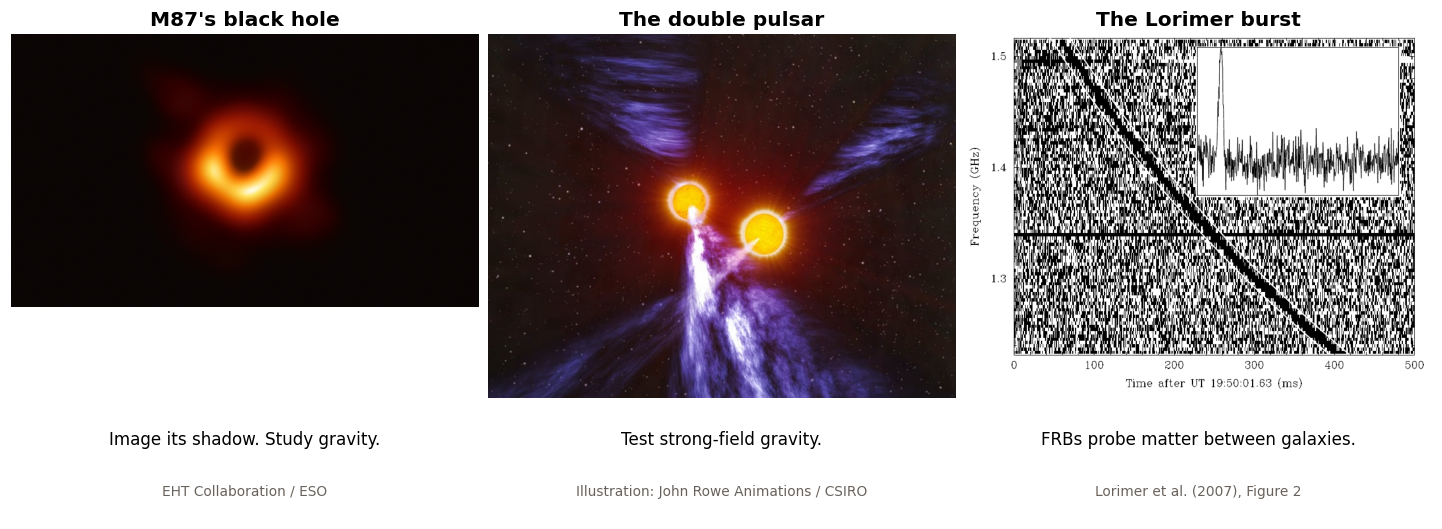

In [3]:
plot_radio_science()
plt.show()

### Faint signals over a wide range of wavelengths

A source with a flux density of 1 jansky is bright in many radio surveys:

$$1\ \mathrm{Jy}=10^{-26}\ \mathrm{W\,m^{-2}\,Hz^{-1}}.$$

This is received power per square metre, per hertz of bandwidth.
Many sources we study are thousands or millions of times fainter.
Radio astronomy spans roughly **0.3 mm to 30 m** in wavelength, five orders of
magnitude. [NRAO: introduction and units](https://www.cv.nrao.edu/~sransom/web/Ch1.html).

### What does a radio telescope measure?

A dish collects radio waves. The electric field drives a voltage in its receiver.
An interferometer measures correlations between antennas to resolve finer detail
on the sky. Unwanted signals from transmitters and electrical equipment are
**radio-frequency interference**, or RFI.

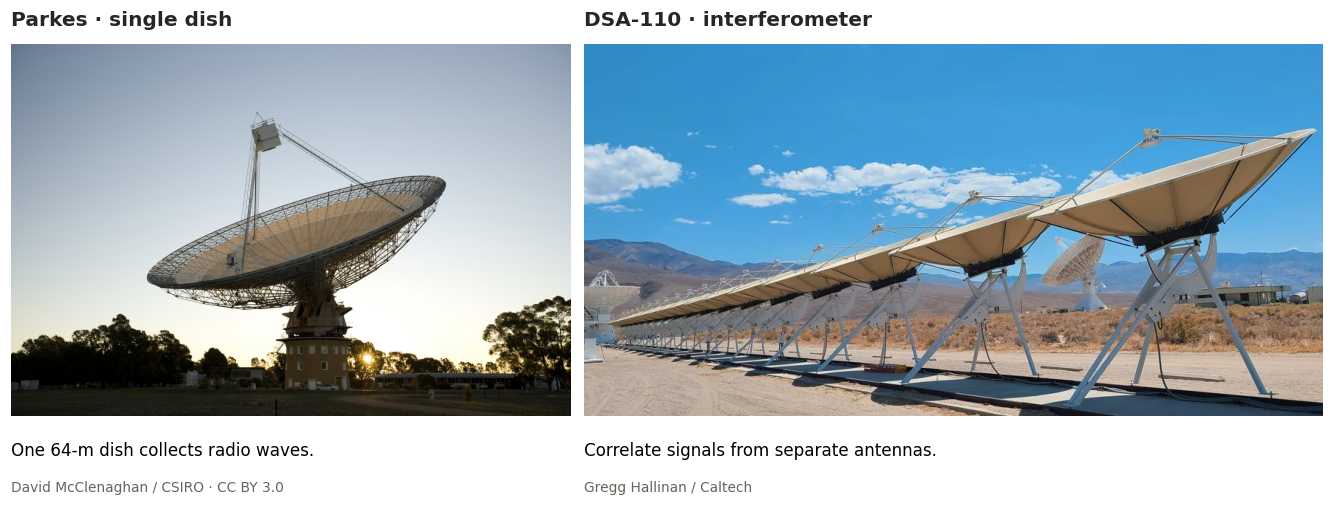

In [4]:
plot_telescopes()
plt.show()

Photos: [Parkes, David McClenaghan / CSIRO](https://commons.wikimedia.org/wiki/File:CSIRO_ScienceImage_7250_The_Radio_Telescope_at_Parkes.jpg)
([CC BY 3.0](https://creativecommons.org/licenses/by/3.0/));
[DSA-110, Gregg Hallinan / Caltech](https://webdev6.ipac.caltech.edu/page/dsa-110).

### I, Q and power

The incoming electric field drives a voltage in the antenna. The receiver
digitizes that voltage and separates it into frequency channels. In each channel,
**I** (in-phase) and **Q** (quadrature) give the amounts of two reference
oscillations, a quarter-cycle apart. Together they retain amplitude and phase.

$$v=I+iQ,\qquad A=\sqrt{I^2+Q^2},\qquad \phi=\mathrm{atan2}(Q,I).$$

The stored values are receiver counts. Antenna response and receiver gain connect
them to the electric field. Power is

$$P=|v|^2=I^2+Q^2.$$

For example, I = 3 and Q = 4 give amplitude 5 and power 25.
Here, I means a voltage component, not astronomical Stokes I.

Ideal receiver noise has Gaussian I and Q. Its power fluctuates strongly.
Our example rounds each component to a 4-bit integer from −8 to 7.
Two components fit in one byte: **4+4-bit** storage. The project uses power arrays.
After rounding, I and Q have discrete levels. More samples fill the histogram
bars; they cannot fill the gaps between integer values.

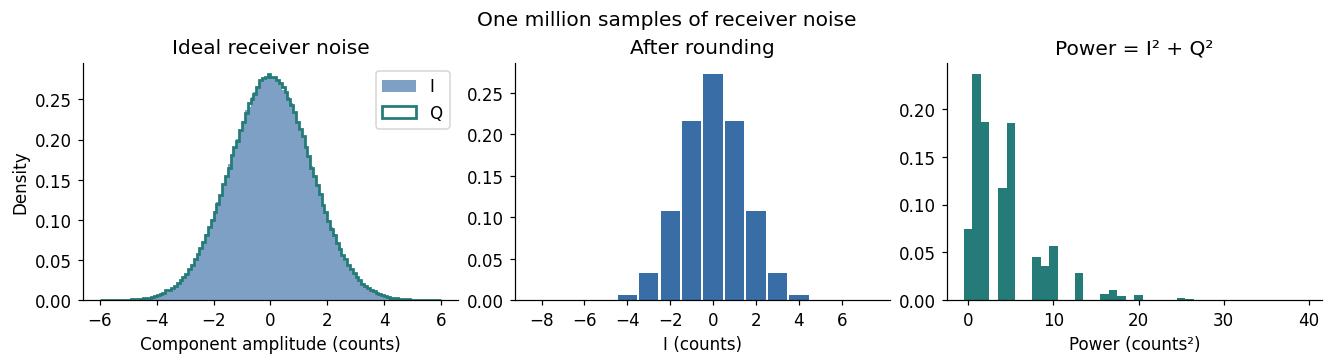

One sample: (-1+3j), power: 10 counts²


In [5]:
ideal = noise((1_000_000,), np.random.default_rng(12))
voltage = quantize(ideal)
power_example = voltage.real**2 + voltage.imag**2
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), layout="constrained")
bins = np.linspace(-6, 6, 121)
axes[0].hist(ideal.real, bins=bins, density=True, alpha=0.65, color="#386da5", label="I")
axes[0].hist(ideal.imag, bins=bins, density=True, histtype="step", lw=1.8, color="#247b78", label="Q")
axes[0].set(title="Ideal receiver noise", xlabel="Component amplitude (counts)", ylabel="Density")
axes[0].legend()
axes[1].hist(voltage.real, bins=np.arange(-8.5, 8.5), density=True, rwidth=0.9, color="#386da5")
axes[1].set(title="After rounding", xlabel="I (counts)")
axes[1].set_xticks(np.arange(-8, 8, 2))
axes[2].hist(power_example, bins=np.arange(-0.5, 40.5), density=True, color="#247b78")
axes[2].set(title="Power = I² + Q²", xlabel="Power (counts²)")
fig.suptitle("One million samples of receiver noise")
plt.show()
print(f"One sample: {voltage[0]}, power: {power_example[0]:g} counts²")

**Polarization** describes the electric field's orientation. It can oscillate
along a line or rotate with right- or left-handed circular polarization.
It helps astronomers study magnetic fields and emission processes.
We use one linear feed, X. [NRAO: polarization](https://www.cv.nrao.edu/~sransom/web/Ch2.html#S3).

### From voltages to an image

| Product | Calculation | Meaning |
| --- | --- | --- |
| Complex voltage | `v = I + iQ` | Signal in one antenna and frequency channel |
| Power | `P = v v* = I² + Q²` | Signal strength, without voltage phase |
| Visibility | $V_{ab}=N^{-1}\sum_n v_a[n]v_b^*[n]$ | Correlation of antennas a and b, averaged over N samples |
| Dirty image | `D = F⁻¹[W V]` | Weighted Fourier imaging; blurred by incomplete sampling |

For antennas a and b, in frequency channel j:

$$\widehat V_{ab}(t_k,\nu_j)=\frac{1}{N}\sum_{n=0}^{N-1}v_a(t_k+n\Delta t,\nu_j)\,v_b^*(t_k+n\Delta t,\nu_j).$$

The averaging interval is $N\Delta t$. The star on `v*` means complex conjugate. In NumPy, one visibility is
`np.mean(v_a * v_b.conj())`. Different antennas give a cross-correlation;
the same antenna gives average power. The image formula assumes a small field
and calibrated data. Imaging needs phase; power alone is not enough.

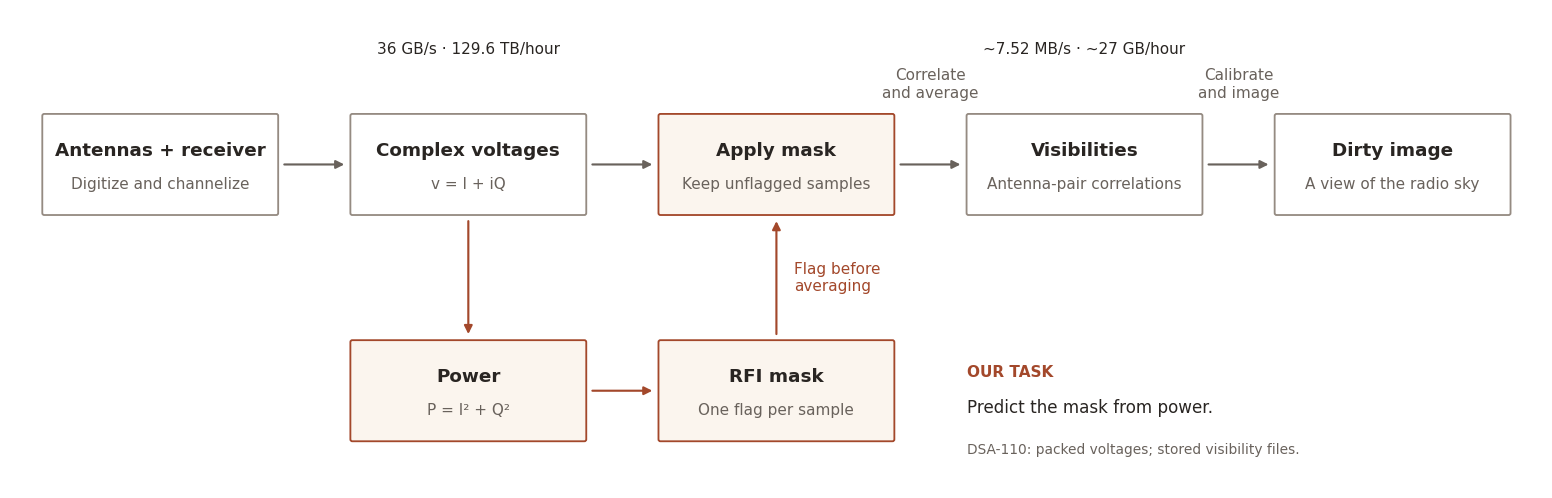

In [6]:
plot_signal_chain()
plt.show()

Read more: [NRAO's interferometry introduction, section 3.7](https://www.cv.nrao.edu/~sransom/web/Ch3.html#S7).

### Where can we remove RFI?

- **Before correlation:** flag voltages or their power. Short flags can retain
  clean samples around an impulse. This is our project.
- **After correlation:** flag visibilities. Many established imaging methods,
  including [AOFlagger](https://arxiv.org/abs/1002.1957), work here.
- **Image domain:** identify contamination in dirty images or fit a source model.

Averaging does not necessarily remove an impulse. Its contribution can contaminate
the whole visibility interval. The original clean and affected times can no longer
be separated. Choose N to suit the science before averaging the correlation products.

**DSA-110 example.** These figures describe the checked 96-input setup and
its saved products. MB and GB are decimal.

| Product | Resolution | Rate | One hour | Stored? |
| --- | --- | --- | --- | --- |
| Packed voltages, 96 antennas, 2 feeds | 32.768 µs; 6,144 × 30.52 kHz channels | **36 GB/s** across the array | **129.6 TB** | Candidate-triggered dumps, typically 2.0–3.1 s; about 72–111 GB |
| Visibilities, XX and YY | **12.885 s**; 768 × 244.14 kHz channels | **4.44 MB/s** complex-value payload; about **7.52 MB/s** in sampled files | **16 GB** payload; about **27 GB** in files | Written to disk for calibration and imaging |

The voltage hour is a continuous-storage estimate; only short dumps are saved.
These visibilities average eight frequency channels and 393,216 time samples.
XX and YY refer to correlations from the telescope's two linear feeds.
A trigger is a candidate, not necessarily a confirmed astronomical event.

For an overview of mitigation methods, read Table 1 in
[Buch et al., with Gregory Hellbourg: Real-time RFI Mitigation Techniques in
Radio Astronomy and their Practical Limitations](https://arxiv.org/html/2512.01954v2#S3).

## 2. What does RFI look like?

These are typical forms of interference seen across different radio telescope instruments.
A satellite can produce a carrier or digital band. Radar uses pulses.
Wireless links transmit in bursts. Electrical discharges produce impulses.
The examples include channel leakage, but are not complete communication protocols.
Receiver noise is omitted here so you can see the injected signals.

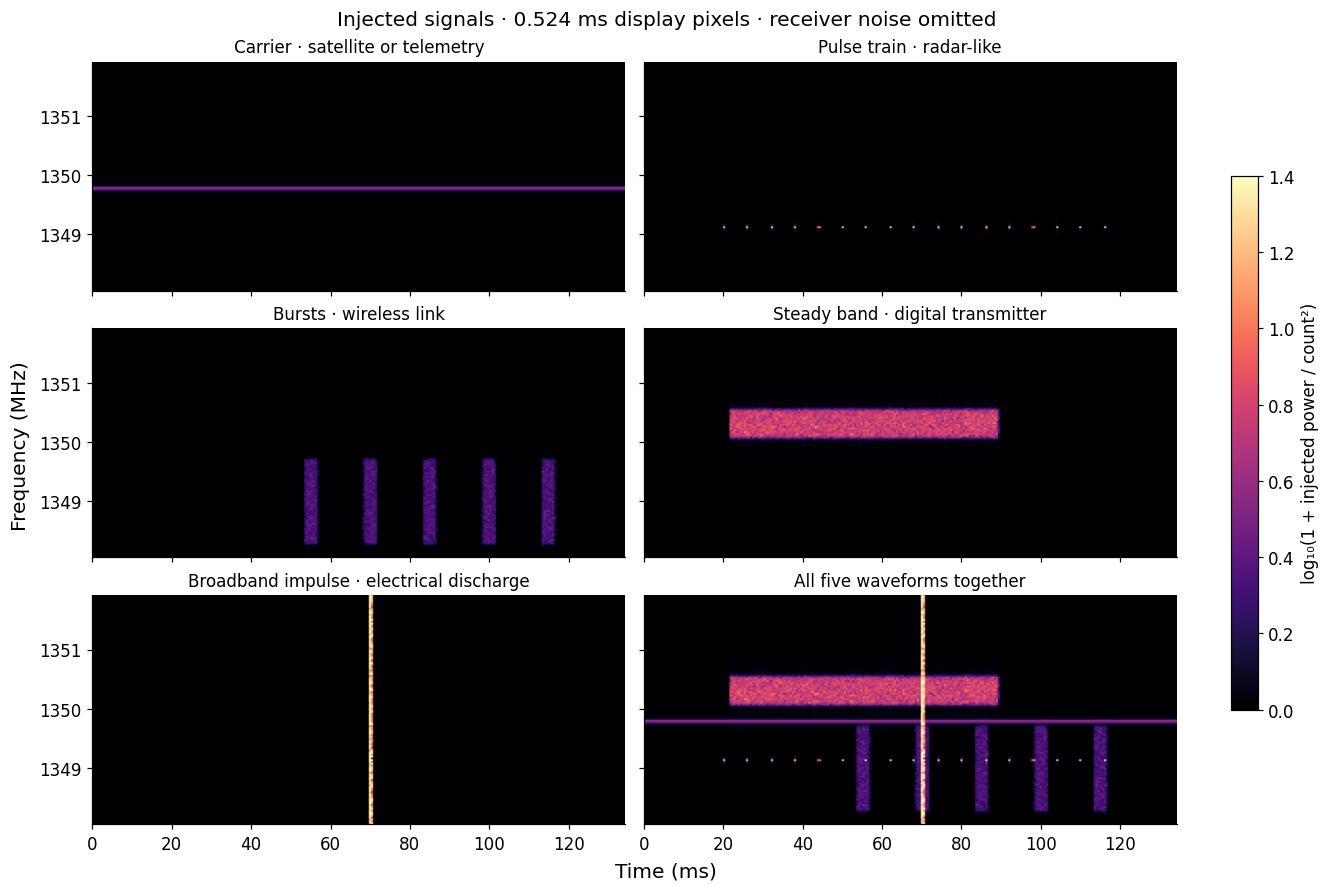

In [7]:
plot_rfi_gallery()
plt.show()

A full satellite pass takes minutes. This example uses a straight overhead track
at 650 km altitude and 7.5 km/s. It shows Doppler shift and distance loss for
an isotropic receiver, without a dish beam. The carrier moves about two channels
over ten minutes. Within 134 ms it is almost stationary.
This display is separate from the training samples.

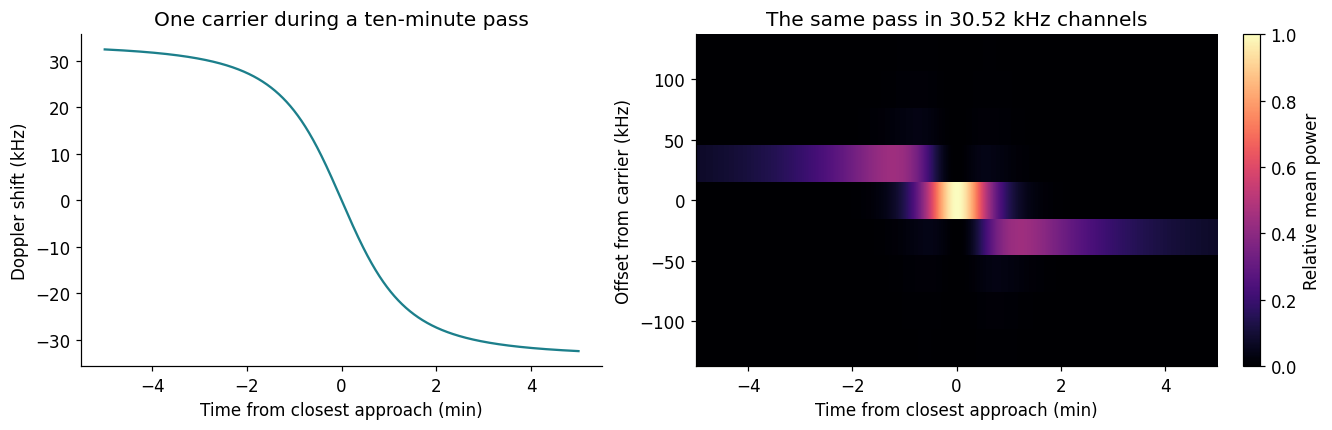

In [8]:
plot_satellite_pass()
plt.show()

**Duty cycle** is the fraction of each cycle when a transmitter is on.
**Modulation** changes its phase, amplitude or frequency to carry information.

| Name | What the transmitter changes |
| --- | --- |
| Binary phase-shift keying (BPSK) | Switches between two phases |
| Quadrature phase-shift keying (QPSK) | Switches between four phases |
| Amplitude-shift keying (ASK) | Changes amplitude |
| Frequency-shift keying (FSK) | Switches between frequencies |

[Smith, Lynch and Pisano (2022)](https://arxiv.org/abs/2207.07642) show that
spectral kurtosis (SK) can miss signals whose power statistics resemble noise. Effective duty cycle
in a channel matters: a transmitter can be on for more than 50% of the time
and still produce a difficult case. Symbol rate and channel filtering affect this.
Our examples include 10%, 50%, 75%, 85% and 100%, with slow and fast modulation.

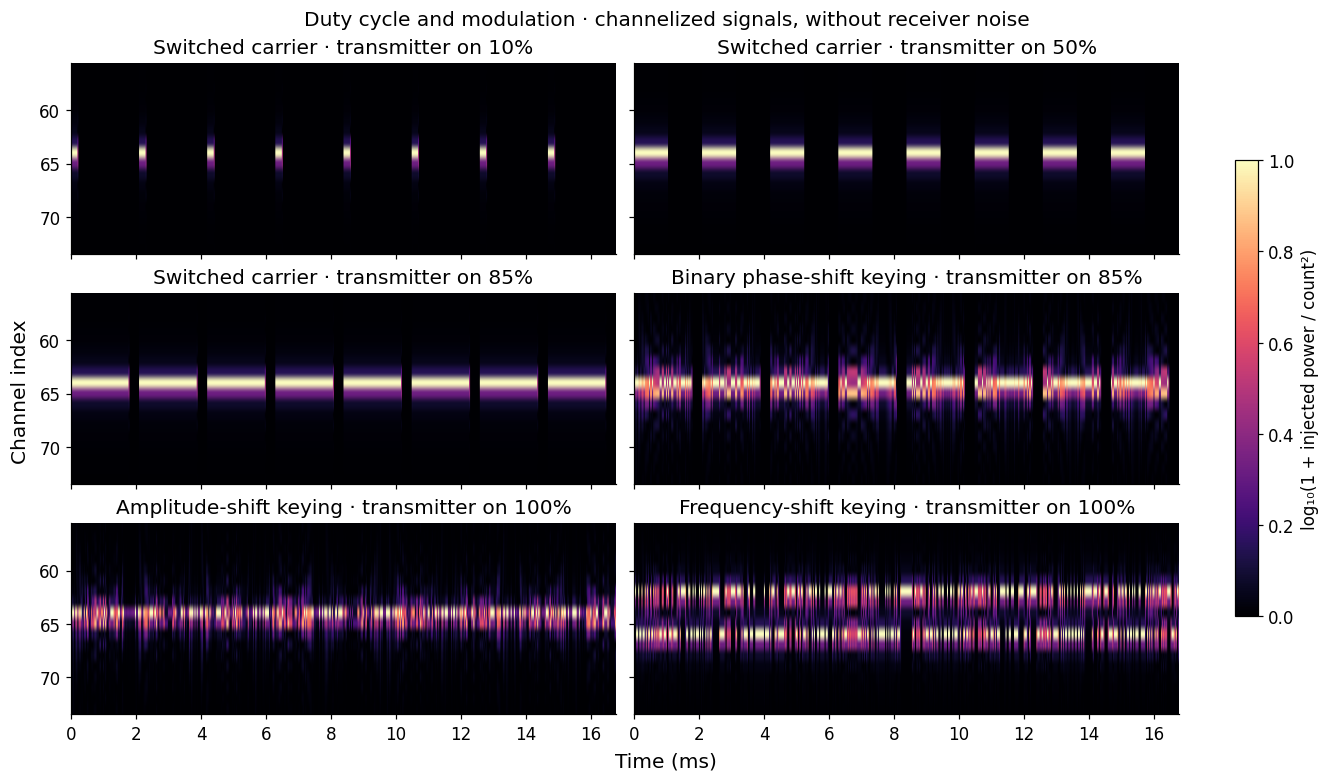

In [9]:
plot_duty_gallery()
plt.show()

## 3. Read one training sample and its label

`dataset.csv` lists every supplied recording. Start with its first five rows.

In [10]:
catalog = pd.read_csv(DATA/"dataset.csv")
display(catalog.head())
display(catalog.groupby("split").size().rename("recordings").to_frame())

,sample_id,split,example,path,rfi_type,duration_s,time_step_us,channels,antennas,reference_power_ratio,peak_power_ratio,mean_power_ratio,label_noise_fraction,labelled_fraction,duty_cycle,symbol_rate,clipped_fraction,parameters
0,1,train,carrier,recordings/0001,carrier,0.134218,32.768,128,10,1.0,1.639620,0.010509,0.01,0.038281,NaN,NaN,3.814697e-07,recordings/0001/recording.json
1,2,train,radar,recordings/0002,radar,0.134218,32.768,128,10,20.0,29.076784,0.000345,0.01,0.000384,0.002991,NaN,5.340576e-06,recordings/0002/recording.json
2,3,train,wireless,recordings/0003,wireless,0.134218,32.768,128,10,1.0,12.079669,0.011071,0.01,0.013225,0.200587,NaN,3.051758e-06,recordings/0003/recording.json
3,4,train,digital,recordings/0004,digital,0.134218,32.768,128,10,1.0,26.653278,0.093079,0.01,0.112961,NaN,NaN,6.504059e-05,recordings/0004/recording.json
4,5,train,impulse,recordings/0005,impulse,0.134218,32.768,128,10,10.0,98.153954,0.021252,0.01,0.002438,NaN,NaN,3.416061e-04,recordings/0005/recording.json


,recordings
split,
test,40
train,100
validation,60


| Columns | Meaning |
| --- | --- |
| `sample_id`, `example`, `rfi_type` | Identifier, example name and signal family |
| `split` | `train` for fitting; `validation` for choosing settings; `test` for final evaluation |
| `path`, `parameters` | Data folder and short JSON file with sampling and simulator settings |
| `duration_s`, `time_step_us`, `channels`, `antennas` | Dimensions and sampling |
| `reference_power_ratio` | Source power / noise power before leakage and antenna gains; 0.1 means 10% |
| `peak_power_ratio`, `mean_power_ratio` | Received injected power / noise power: maximum and mean over the recording |
| `duty_cycle`, `symbol_rate` | On-time fraction within a cycle and symbols per second; blank when not applicable |
| `label_noise_fraction`, `labelled_fraction` | Label cutoff relative to noise power; fraction of samples labelled RFI |
| `clipped_fraction` | Fraction of samples with a component beyond the quantizer range |

All three splits are included. Keep all antennas and windows from one recording
in the same split. Choose settings on validation data, then evaluate once on test.
Neighboring samples are not independent experiments.
Strength and labels are for evaluation, not model inputs.

Input power: (4096, 128) float32
Target mask: (4096, 128) bool
Split: train Antenna: A00


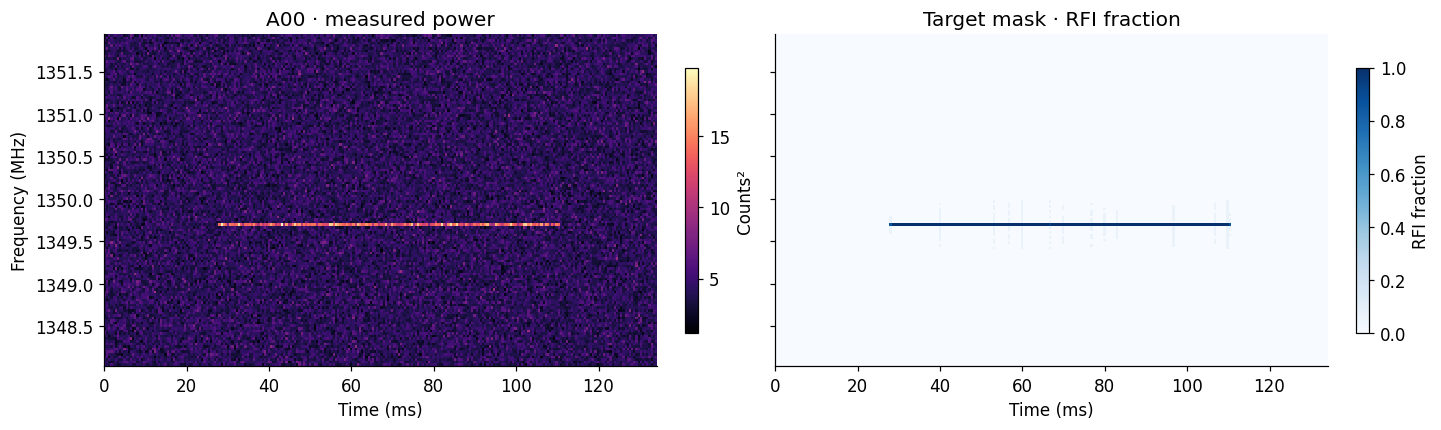

In [11]:
sample = load_sample(DATA, sample_id=18, antenna=0)
power = sample["power"]
labels = sample["rfi_mask"]
print("Input power:", power.shape, power.dtype)
print("Target mask:", labels.shape, labels.dtype)
print("Split:", sample["split"], "Antenna:", sample["antenna_names"][0])
plot_sample(sample, factor=16)
plt.show()

**This is the supervised segmentation pair.** Left: input power. Right: target
mask with the same time–frequency coordinates. A **flag** is a detector's
prediction that a sample should be removed. Neither mask changes the stored power.

The target is `True` where injected power is **at least 1% of the mean receiver-noise
power**. It is `False` below that cutoff, including faint leakage. Every sample is
scored. A flag below the cutoff counts as a false positive. The cutoff defines
the task; it does not guarantee that RFI is visible in one noisy sample.

This narrow-band transmitter uses binary phase-shift keying. Both panels show
the full 134 ms recording, averaged over 16 samples for display. The label panel
shows the fraction of positive labels in each display pixel. The stored target
is binary at native resolution.

| Axis | One training sample | Full recording |
| --- | --- | --- |
| Time | 4,096 values, 32.768 µs apart; 134.218 ms | Same |
| Frequency | 128 channels, 30.52 kHz apart; 3.91 MHz near 1350 MHz | Same |
| Antenna | One selected antenna | 10, A00–A09 |
| Feed | Linear X, removed from the sample axes | One |

This critically sampled channelizer has `Δt = N_channels / bandwidth`:
`128 / 3,906,250 Hz = 32.768 µs`. Display averaging is a separate choice.

The ZIP has **200 recordings**: 100 train, 60 validation and 40 test.
Each has ten antennas: **1,000 training pairs, 600 validation pairs and 400 test pairs**.
The ten antennas share transmitters; they are not ten independent recordings.
There are 180 RFI recordings, ten noise-only controls and ten astronomical-pulse controls.
Arrays use NumPy `.npy` files for partial reads. Power is stored as uint8 without
loss from the quantized values. The loader returns float32.

### Read all antennas from the same time interval

RFI can reach a few antennas or the whole array. Its received strength can differ.
All panels share time, frequency and colour scale. They are simultaneous
measurements, not ten unrelated injections.

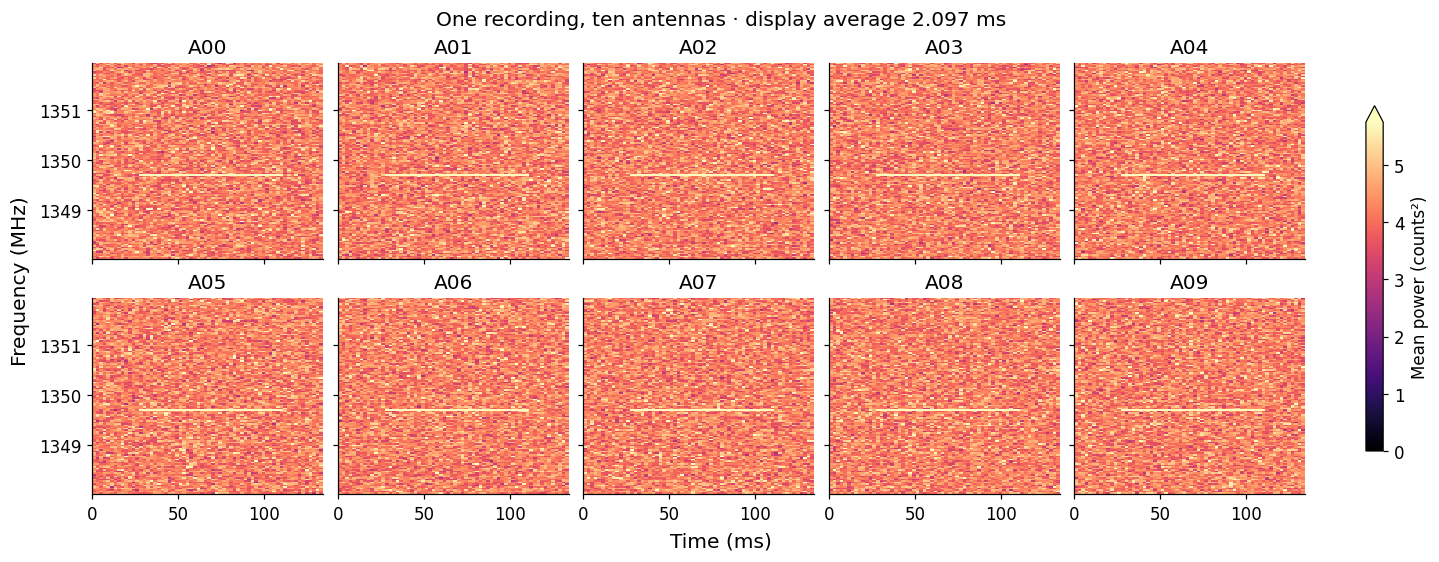

In [12]:
row = catalog.set_index("sample_id").loc[18]
recording = load_recording(DATA/row["path"])
plot_antenna_grid(recording, factor=64)
plt.show()

This grid averages 64 samples for display: **2.097 ms per pixel**.
Data and labels stay at native resolution. Use `factor=1` to see native samples.
`load_sample(DATA, sample_id=18, antenna=7)` selects A07 from this recording.
Here, all antennas receive the transmitter at the same time, with different strengths.

## 4. Run the baseline

This baseline is similar to the flagger currently used at DSA-110.
It uses the production spectral-kurtosis and bandpass detector code.

- `sk`: tests power fluctuations within each channel.
- `bandpass`: tests a channel's average power against other channels.
- `sk-bandpass`: combines both masks and expands clusters along frequency.

A detection marks the whole 134 ms antenna–channel block. Its mask can cover
more time than a pulse. Every removed native sample counts in the score.
Each antenna is tested separately. A flag on A00 does not flag A01–A09.

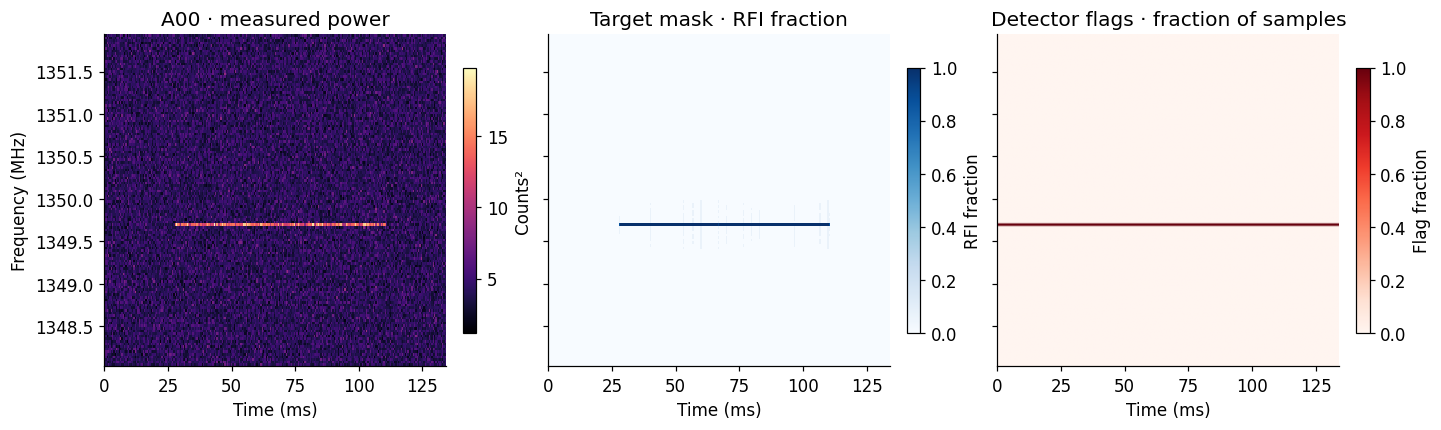

A00: 1 of 128 channels flagged for this block.


In [13]:
sk_mask = flag_rfi(power, method="sk")
bandpass_mask = flag_rfi(power, method="bandpass")
baseline_mask = flag_rfi(power, method="sk-bandpass")
plot_sample(sample, baseline_mask, factor=16)
plt.show()
print(f"A00: {baseline_mask[0].sum()} of {power.shape[1]} channels flagged for this block.")

### Spectral kurtosis

For M power values in one channel:

$$S_1=\sum_{n=1}^{M}P_n,\quad S_2=\sum_{n=1}^{M}P_n^2,\quad \widehat{\mathrm{SK}}=\frac{M+1}{M-1}\left(\frac{M S_2}{S_1^2}-1\right).$$

SK is near 1 for ideal Gaussian voltage noise. A value outside its lower and
upper thresholds triggers a flag. It uses power fluctuations, not just average
power. Quantization and finite samples affect its distribution.
The reference uses M = 64, 256, 1024 and 4096 and combines their detections.
[Nita and Gary: the estimator](https://arxiv.org/abs/1005.4371).

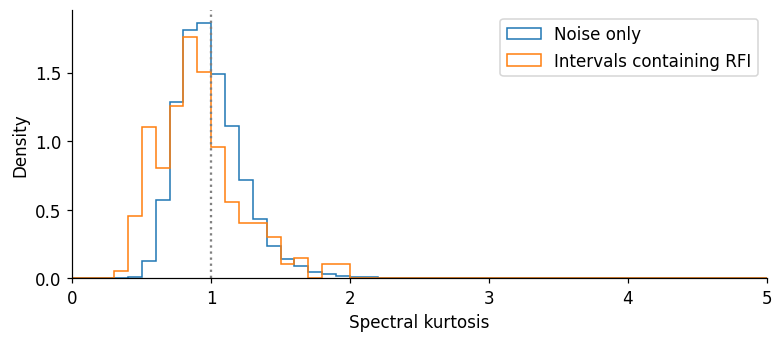

M = 64   interval = 2.097 ms


In [14]:
m = 64
s1, s2 = power_sums(power, m)
sk = spectral_kurtosis(s1, s2, m)
clean_id = int(catalog.query("split == 'validation' and rfi_type == 'clean'").iloc[0].sample_id)
clean = load_sample(DATA, sample_id=clean_id, antenna=0)
clean_s1, clean_s2 = power_sums(clean["power"], m)
clean_sk = spectral_kurtosis(clean_s1, clean_s2, m)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
bins = np.linspace(0, 5, 51)
contains_rfi = average_power(labels, m) > 0
ax.hist(clean_sk.ravel(), bins=bins, density=True, histtype="step", label="Noise only")
ax.hist(sk[contains_rfi], bins=bins, density=True, histtype="step", label="Intervals containing RFI")
ax.axvline(1, color="grey", ls=":")
ax.set(xlabel="Spectral kurtosis", ylabel="Density", xlim=(0, 5))
ax.legend()
plt.show()
print("M =", m, "  interval =", round(m*32.768/1000, 3), "ms")

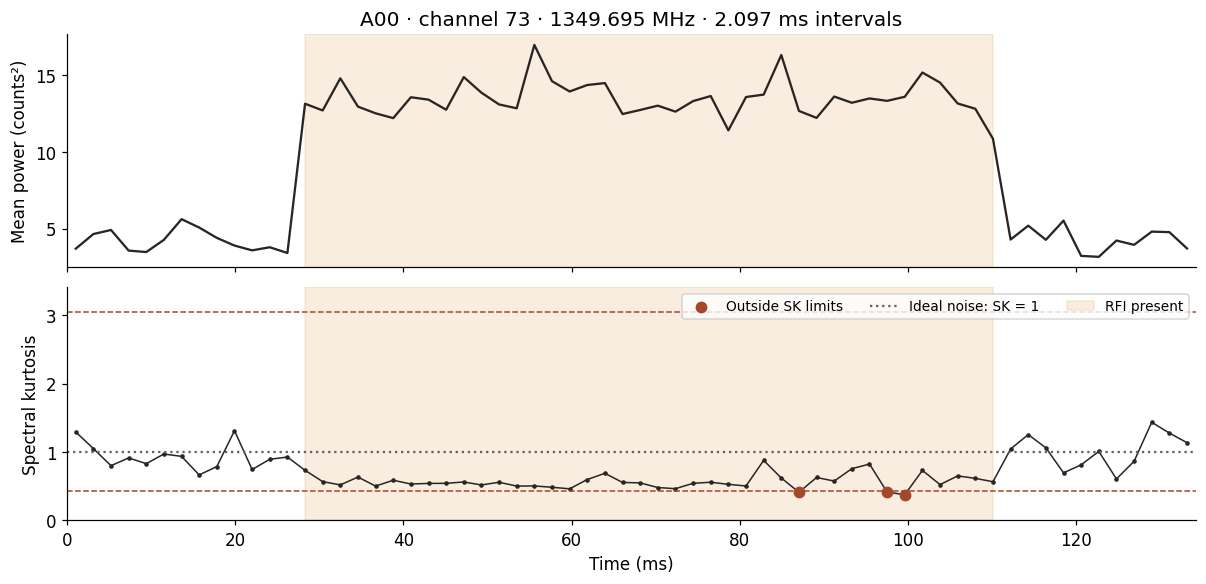

In [15]:
plot_kurtosis(sample, m=64)
plt.show()

The orange histogram selects intervals that contain labelled RFI.
The time plot follows the brightest channel in A00. Shading marks intervals
with labelled RFI. Dashed lines are the SK detector limits for M = 64; red dots
cross a limit. Here, RFI makes SK fall below the lower limit.
We use labels only to explain the result, not as input to the detector.

### Bandpass outlier

Average each channel over a 4,096-sample block: `B_c = mean(P_c)`.
Across channels, calculate `b = median(B)` and
`s = 1.4826 × median(|B − b|)`. Flag channel c when `|B_c − b| > k s`.
The reference code sets k for this channel count. Keep its default for this exercise.
A steady carrier can change B while leaving some fluctuation tests ineffective.
A broad band can raise the reference itself and become harder to detect.

## 5. Score the masks

A true positive (TP) is correctly flagged RFI. A false positive (FP) is a
flag where the target mask is zero. A false negative (FN) is missed labelled RFI.
A true negative (TN) has a zero target and stays unflagged.

**Precision = TP / (TP + FP):** what fraction of flags are correct?
**Recall = TP / (TP + FN):** what fraction of labelled RFI was found?
**False-positive rate = FP / (FP + TN):** what fraction of negative samples was flagged?
Also report the total fraction removed.
Precision is undefined when there are no flags. Recall is zero when a detector
misses all positive labels, and undefined when there are no positive labels.

,precision,recall,false_positive_rate,removed
sk,61.6%,93.9%,0.3%,0.8%
bandpass,61.6%,93.9%,0.3%,0.8%
sk-bandpass,61.6%,93.9%,0.3%,0.8%


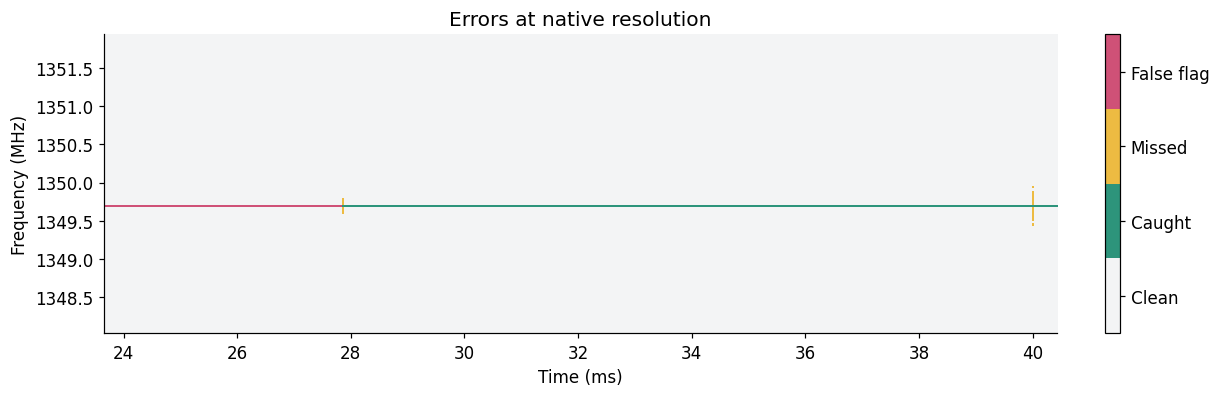

In [16]:
masks = {"sk": sk_mask, "bandpass": bandpass_mask, "sk-bandpass": baseline_mask}
scores = pd.DataFrame({name: score_mask(mask, labels) for name, mask in masks.items()}).T
display(scores[["precision", "recall", "false_positive_rate", "removed"]].style.format("{:.1%}", na_rep="—"))
first = max(0, int(np.flatnonzero(labels.any(axis=1))[0])-128) if labels.any() else 0
first = min(first, len(power)-512)
plot_errors(sample, baseline_mask, first=first)
plt.show()

Here the three methods flag the same main channel. Precision is below 100%
because they also remove times before and after the transmission. Some labelled
power outside that channel is missed. This selected teaching example is not a
summary of performance across the dataset. Try recording 4 to see different masks.

Keep the reference settings fixed for the first comparison.
To study accumulation length later, use `m_values=(64,)` or `(256,)`.
Bandpass still averages the full block. M = 1 works for displaying native power,
but not for SK. Baseline windows must start at multiples of 4,096.

A simple native-power threshold helps distinguish the benefit of short flags
from the benefit of a neural network.

In [17]:
short_sk = flag_rfi(power, method="sk", m_values=(64,))
threshold = float(np.quantile(clean["power"], 0.999))
native_mask = flag_power(power, threshold)
print("Native power threshold:", threshold, "counts²")
display(pd.DataFrame({"SK, M=64": score_mask(short_sk, labels),
                      "native power": score_mask(native_mask, labels)}).T[
                          ["precision", "recall", "false_positive_rate", "removed"]])

Native power threshold: 29.0 counts²


,precision,recall,false_positive_rate,removed
"SK, M=64",0.615967,0.938616,0.003016,0.007812
native power,0.307102,0.059524,0.000692,0.000994


## 6. Make a controlled example

Keep the seed fixed while changing one parameter. This keeps receiver noise fixed.
`strength=10` sets reference on-state power to ten times the noise power. Leakage,
pulse width and antenna gains affect received power in a channel.
For a pulsed carrier, `duty_cycle=0.85` keeps the transmitter on for 85% of each cycle.
The returned arrays are channelized power and binary truth.

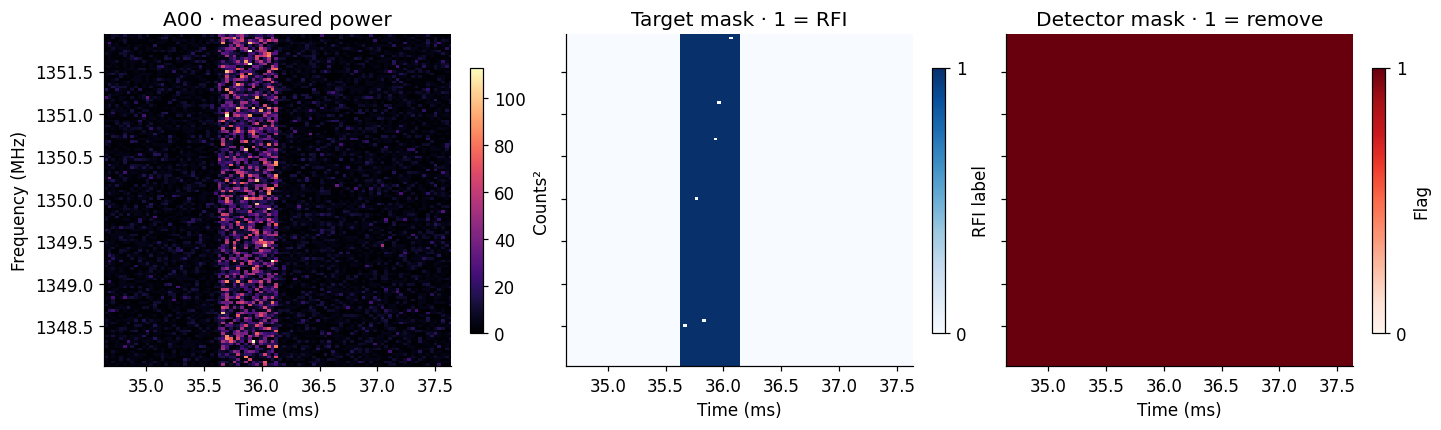

In [18]:
generated = simulate_recording(seed=52, rfi="impulse", strength=10)
prediction = flag_rfi(generated["power"], method="sk-bandpass")
burst_ms = generated["metadata"]["events"][0]["start_s"]*1000
plot_sample(generated, prediction, antenna=0, factor=1,
            time_ms=(burst_ms-1, burst_ms+2))
plt.show()

This broadband impulse is a harder case. It raises power in most channels
briefly. The bandpass test can miss a rise shared across the band. Spectral
kurtosis and channel expansion can flag the entire block. That catches the
impulse but discards much more data than its short duration requires.

**Save once, read later.** The default lasts 134 ms. Use `duration_s=4` for
about four seconds, rounded up to whole processing blocks. The reader handles
block boundaries. Longer recordings need more memory; start with the default.

In [19]:
output = Path("outputs/my_impulse_v1.0")
if not output.exists():
    save_recording(output, generated)
saved = load_recording(output, start=0, samples=4096)
np.testing.assert_array_equal(saved["power"], generated["power"])
np.testing.assert_array_equal(saved["rfi_mask"], generated["rfi_mask"])
print(output)

outputs/my_impulse_v1.0


### Keep astronomical bursts

This control contains a bright, dispersed astronomical pulse and receiver noise,
with **no RFI**. Lower frequencies arrive later. The existing RFI mask is zero
everywhere: this is a signal to keep. Both panels show antenna A00.
Power is averaged over 64 samples for display; stored data and scores use native samples.
Test whether a detector preserves the pulse. Fainter astronomical signals need separate checks.

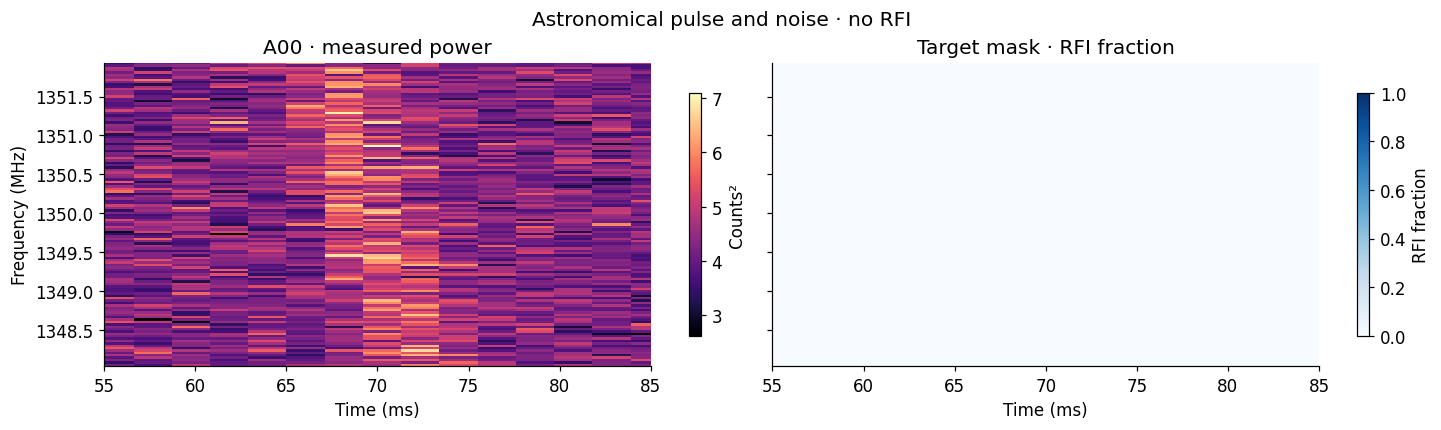

RFI labels: 0


In [20]:
sky_id = int(catalog.query("split == 'validation' and rfi_type == 'sky'").iloc[0].sample_id)
sky = load_sample(DATA, sample_id=sky_id, antenna=0)
fig = plot_sample(sky, factor=64, time_ms=(55, 85))
fig.suptitle("Astronomical pulse and noise · no RFI")
plt.show()
print("RFI labels:", sky["rfi_mask"].sum())

## 7. Tasks

### Bring to the next meeting

Work as one team. Each person should be able to load a sample and explain its mask.

1. Run `sk`, `bandpass` and `sk-bandpass`. Tabulate precision, recall,
   false-positive rate and removal fraction for each RFI family.
2. Plot one input with its label and each detector's mask. Explain one miss
   and one false flag. Change one parameter to test your explanation.
3. Compare 10%, 50%, 75%, 85% and 100% duty cycles. Plot recall against duty
   cycle for each detector. Keep strength, period and the noise seed fixed.
4. Each person reads one ML RFI paper. Bring one figure and fill one row below.

| Paper (author et al.) | Dataset: simulated or real | Telescope: dish or interferometer | Modality | Method / ML architecture | Metrics and test split |
| --- | --- | --- | --- | --- | --- |
| Your choice | | | | | |

Suggested papers, one per person:

1. [Akeret et al.: RFI mitigation using deep convolutional neural networks](https://arxiv.org/abs/1609.09077).
2. [Vafaei Sadr et al.: Deep learning improves identification of RFI](https://arxiv.org/abs/2005.08992).
3. [Yang et al.: Deep residual detection of RFI for FAST](https://arxiv.org/abs/2001.06669).
4. [Kerrigan et al.: Optimizing sparse RFI prediction using deep learning](https://arxiv.org/abs/1902.08244).

**You can choose any ML RFI mitigation paper you like.** These are suggestions.
Compare label definitions and test splits before comparing reported scores.
Smith et al. is extra reading for the baseline, not one of the ML choices.

### Train a small U-Net

Input: one antenna's native power, shape `(4096, 128)`.
Target: its binary RFI mask. Output: one RFI probability per time–frequency pixel.
A PyTorch batch has shape `(batch, 1, 4096, 128)` for both input and target.
The `1` is one power image, not ten antennas combined. Threshold the output
probabilities to produce a Boolean mask. Each antenna is a separate training pair.
Share weights across antennas. Do not feed SK, labels, sample IDs or
transmitter parameters into the network.

Start with the supplied training split. For this ideal dataset, pool the power
values from **all noise-only training recordings** (`split == 'train'` and
`rfi_type == 'clean'`) across time, frequency and antennas. Calculate **one mean
and one standard deviation** from those pooled values. Use `(power - mean) / std`
for every U-Net input in train, validation and test. Do not calculate a separate
normalization for each recording. Leave labels unchanged and give the classical
detectors the original, unnormalized power.

Choose the output threshold and other settings on validation data. Keep them fixed
before scoring the test split. Compare at a matched clean-validation false-positive
rate, and also retain the baseline reference setting. A GPU runtime is useful for training.

For more training data, use new seeds and vary strength, location, duration,
duty and modulation. Keep the supplied validation and test recordings unchanged.

Include these plots in the report:

- Input, truth and predicted mask for one success and one failure.
- Precision–recall curves and average precision for the U-Net. Add baseline
  points for the three fixed baseline masks. One hard mask does not define
  a precision–recall curve.
- Recall versus source power as a percentage of noise power, for each family.
  Record both reference strength and received peak power.
- Recall versus duty cycle, separately for each modulation.
- Clean data removed and astronomical signal retained. Select the `clean` and
  `sky` controls from the CSV. The astronomical pulse has no RFI labels.
  Do not treat it as an unwanted burst. A bright pulse can appear in single-antenna power.



Further reading: [Buch et al. on RFI mitigation methods (Table 1)](https://arxiv.org/html/2512.01954v2#S3),
[Price on channelizers](https://arxiv.org/abs/1607.03579),
[Smith et al. on SK failure cases](https://arxiv.org/abs/2207.07642), and
[NRAO on short-pulse blanking](https://science.nrao.edu/facilities/vla/docs/manuals/opt-manual/resource-catalog-tool/rfi-blanking).
Experiments work offline after installation. Reading links need internet.